## Import das Bibliotecas

In [35]:
import matplotlib.pyplot as plt  # plots
import numpy as np  # vectors and matrices
import pandas as pd  # tables and data manipulations
import seaborn as sns  # more plots
import duckdb #conexão com banco de dados duckdb
import os
import holidays
sns.set()
import warnings  
warnings.filterwarnings("ignore")

# Modelos Utilizados
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
import lightgbm as lgb

# biblioteca que gera o forecast
from mlforecast import MLForecast

# bibliotecas de avaliação de resultados
from utilsforecast.losses import mae, mape, rmse, smape
from utilsforecast.preprocessing import fill_gaps

# biblioteca para tratativa de datas
from datetime import datetime

# plotar as séries
from utilsforecast.plotting import plot_series

# utilizado para calcular a sazonalidade da série
from statsmodels.tsa.stattools import acf

from statsforecast import StatsForecast
from statsmodels.tsa.seasonal import seasonal_decompose 

## Funções 

In [36]:
# função para detectar o valor de ACF para cada série
def detecta_season(series,max_lag=100):
	acf_values= acf(series,nlags=max_lag,fft=True)
	season_lag = np.argmax(acf_values[1:])+1
	return season_lag

In [37]:
def loss(metrica,df, modelos=[],id_col='unique_id', target_col='y_orig'):
    df_metrica_final = pd.DataFrame()
    for periodo in df.periodo.unique():
        df_temp = metrica(df.query(f"periodo=='{periodo}'"),models=modelos,
                id_col='unique_id', target_col='y_orig')
        df_temp['periodo'] = periodo
        if df_metrica_final.shape[0] ==0:
            df_metrica_final = df_temp
        else:
            df_metrica_final = pd.concat([df_metrica_final,df_temp])
        
    df_temp = metrica(df,models=modelos,id_col='unique_id', target_col='y_orig')
    df_temp['periodo'] = 'TOTAL'
    df_metrica_final = pd.concat([df_metrica_final,df_temp])
    return df_metrica_final

## Variáveis

In [38]:
USUARIO = 'luizh'
DB_PATH = rf"c:\Users\{USUARIO}\Documents\DB\anac_prod.db"

AEROPORTO = input("Digite o Código IATA do Aeroporto Desejado: (Ex: GRU, CGH, VCP, etc): ")
NATUREZA = input("Voo DOMÉSTICA ou INTERNACIONAL? (Digite D ou I. OBS: Para ambos, aperte Enter): ")

ARQUIVO_EXCEL = rf"C:\Users\{USUARIO}\Documents\workspace\ML"

def natureza_etapa(natureza):
    if natureza.upper() == 'D':
        return "AND a.ds_natureza_etapa = 'DOMÉSTICA'"
    elif natureza.upper() == 'I':
        return "AND a.ds_natureza_etapa = 'INTERNACIONAL'"
    else:
        return None

def natureza(natureza):
    if natureza.upper() == 'D':
        return "DOMÉSTICA"
    elif natureza.upper() == 'I':
        return "INTERNACIONAL"

In [39]:

# ler arquivo do banco de dados
def consulta_duckdb() -> pd.DataFrame:
    conn = duckdb.connect(DB_PATH)
    try:
        pandas_df = conn.execute(f"""
        SELECT 
            DATE(a.dt_partida_real) AS data
            ,a.sg_iata_origem 
            ,SUM(a.nr_passag_pagos) + SUM(a.nr_passag_gratis) AS PAX
        FROM main.anac a
        WHERE 1=1 
            AND a.sg_iata_origem = '{AEROPORTO.upper()}'
            AND YEAR(data) >= 2023
            AND data <= '2026-09-30'
            {natureza_etapa(NATUREZA)}
        GROUP BY ALL
        ORDER BY DATE(a.dt_partida_real)""").df()
        print(f"Consulta concludída: {len(pandas_df)} registros")
        return pandas_df
    finally:
        conn.close()

## Importando Dados

In [40]:
# ler os dados do banco/ arquivo com o formato abaixo
# Arquivo de trÊs colunas 
# unique_id = ID da série (nome aeroporto por exemplo)
# ds = unidade de tempo (dia, mes, ano, etc.)
# y = valores (número de passageiros por exemplo)
# pandas_df = nome_do_dataframe
if 'ANAC.xlsx' in os.listdir(rf'{ARQUIVO_EXCEL}'):
    pandas_df = pd.read_excel('ANAC.xlsx',sheet_name='Report')
else:
    pandas_df = consulta_duckdb()

pandas_df.rename(columns={"data":'ds','sg_iata_origem':'unique_id','PAX':'y'},inplace=True)
pandas_df.tail()

Consulta concludída: 1351 registros


,ds,unique_id,y
1346,2026-09-26,FOR,734.0
1347,2026-09-27,FOR,825.0
1348,2026-09-28,FOR,658.0
1349,2026-09-29,FOR,1211.0
1350,2026-09-30,FOR,394.0


## Trata os dados

In [41]:
#data máxima de dados na base
print(f"data min = {pandas_df.ds.min()} data max = {pandas_df.ds.max()}")

data min = 2023-01-01 00:00:00 data max = 2026-09-30 00:00:00


In [42]:
pandas_df.ds = pd.to_datetime(pandas_df.ds ,  format='%Y-%m-%d')

In [43]:
#transformação de oferecidas em escala de log
pandas_df['y_orig'] = pandas_df['y']
pandas_df['y'] = np.log1p(pandas_df['y'])


In [44]:
pandas_df.dtypes

ds           datetime64[us]
unique_id            object
y                   float64
y_orig              float64
dtype: object

In [45]:
pandas_df = pandas_df.sort_values(by=['unique_id', 'ds']).reset_index(drop=True)

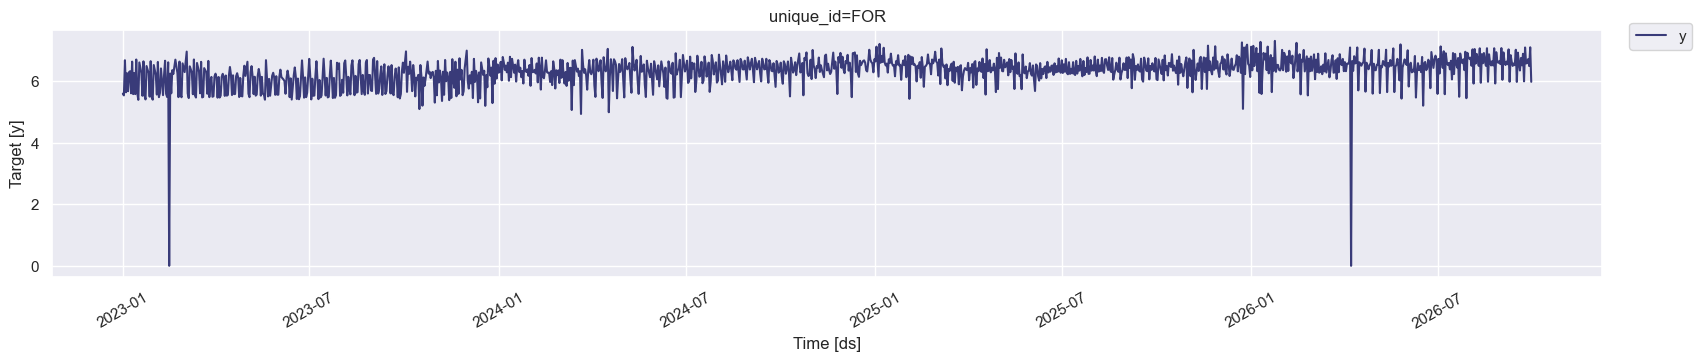

In [46]:
#Gera o gráfico com o resultado da série ao longo do tempo
StatsForecast.plot(pandas_df,target_col='y')


In [47]:
unique_id = {AEROPORTO}
# Gera a decomposição de uma série ao longo do tempo
#pandas_df = dataframe gerado a partir dos dados do banco

for unique_id in pandas_df.query("unique_id ==@@unique_id").unique_id.unique():
    a = seasonal_decompose(pandas_df.query("unique_id==@@unique_id")
                 ["y"], model = "add", period=20)
    a.plot();
    print(f"*********************************Decomposição=={unique_id}*************************************")
    

In [48]:

# Calendário de feriados brasileiros
calendario = holidays.country_holidays(
    'BR',
    years=[2024, 2025, 2026, 2027]
)

# Criar calendário diário
datas = pd.date_range(
    start='2024-01-01',
    end='2027-12-31',
    freq='D'
)

df_calendario = pd.DataFrame({
    'ds': datas
})

# Identificar feriados
df_calendario['eh_feriado'] = (
    df_calendario['ds']
    .dt.date
    .isin(calendario)
    .astype(int)
)

print(df_calendario[df_calendario['eh_feriado'] == 1])


             ds  eh_feriado
0    2024-01-01           1
88   2024-03-29           1
111  2024-04-21           1
121  2024-05-01           1
250  2024-09-07           1
285  2024-10-12           1
306  2024-11-02           1
319  2024-11-15           1
324  2024-11-20           1
359  2024-12-25           1
366  2025-01-01           1
473  2025-04-18           1
476  2025-04-21           1
486  2025-05-01           1
615  2025-09-07           1
650  2025-10-12           1
671  2025-11-02           1
684  2025-11-15           1
689  2025-11-20           1
724  2025-12-25           1
731  2026-01-01           1
823  2026-04-03           1
841  2026-04-21           1
851  2026-05-01           1
980  2026-09-07           1
1015 2026-10-12           1
1036 2026-11-02           1
1049 2026-11-15           1
1054 2026-11-20           1
1089 2026-12-25           1
1096 2027-01-01           1
1180 2027-03-26           1
1206 2027-04-21           1
1216 2027-05-01           1
1345 2027-09-07     

# Gera o forecast para todos os grupos

In [49]:

from utilsforecast.preprocessing import fill_gaps

# 1. Preparar a base histórica e o calendário
pandas_df['ds'] = pd.to_datetime(pandas_df['ds'])
df_calendario['ds'] = pd.to_datetime(df_calendario['ds'])

# Evitar duplicações no calendário
df_calendario = (
    df_calendario[['ds', 'eh_feriado']]
    .drop_duplicates(subset=['ds'])
)

pandas_df = pandas_df.drop(
    columns=['eh_feriado'],
    errors='ignore'
).merge(
    df_calendario,
    on='ds',
    how='left',
    validate='many_to_one'
)

pandas_df['eh_feriado'] = (
    pandas_df['eh_feriado'].fillna(0).astype(int)
)

# 2. Separar treinamento: somente dados anteriores a 2026
Y_train_df = pandas_df[
    pandas_df['ds'] < '2026-01-01'
].copy()

# 3. Verificar datas duplicadas antes do fill_gaps
duplicadas = Y_train_df.duplicated(
    subset=['unique_id', 'ds'],
    keep=False
)

if duplicadas.any():
    print(
        Y_train_df.loc[
            duplicadas,
            ['unique_id', 'ds', 'y']
        ].sort_values(['unique_id', 'ds'])
    )

    raise ValueError(
        "Existem datas duplicadas por aeroporto. "
        "Corrija-as antes de executar fill_gaps."
    )

# 4. Completar as datas faltantes em cada série
Y_train_df = fill_gaps(
    Y_train_df,
    freq='D',
    id_col='unique_id',
    time_col='ds'
)

# Preencher lacunas de passageiros com zero
# Somente se a ausência de registro significar zero passageiros
Y_train_df['y'] = Y_train_df['y'].fillna(0)

# Preencher a informação de feriado nas novas datas
Y_train_df['eh_feriado'] = (
    Y_train_df['eh_feriado'].fillna(0).astype(int)
)

# 5. Configurar os modelos
models = [
    lgb.LGBMRegressor(random_state=0, verbosity=-1),
    LinearRegression(),
    KNeighborsRegressor(n_neighbors=5)
]

fcst = MLForecast(
    models=models,
    freq='D',
    lags=[1, 7, 14, 21, 28],
    date_features=['dayofweek', 'month']
)

# 6. Treinar os modelos
fcst.fit(
    Y_train_df[
        ['unique_id', 'ds', 'y', 'eh_feriado']
    ],
    id_col='unique_id',
    time_col='ds',
    target_col='y',
    static_features=[]
)

# 7. Identificar as datas de 2026 já existentes na base
dados_2026 = pandas_df[
    pandas_df['ds'] >= '2026-01-01'
].copy()

if dados_2026.empty:
    raise ValueError("Não existem datas de 2026 na base.")

# Última data disponível em 2026
data_maxima = dados_2026['ds'].max()

# Prever desde o primeiro dia de 2026 até 60 dias após
# a data máxima encontrada na base
data_inicio = pd.Timestamp('2026-01-01')
data_final = data_maxima + pd.Timedelta(days=60)

# Horizonte necessário para cada série
ultimas_datas = (
    Y_train_df.groupby('unique_id')['ds']
    .max()
)

horizontes = (
    data_final - ultimas_datas
).dt.days

if (horizontes <= 0).any():
    raise ValueError(
        "Verifique se todas as séries possuem dados de treinamento "
        "anteriores à data final da previsão."
    )

# MLForecast utiliza um horizonte comum para todas as séries
H = int(horizontes.max())

# 8. Gerar datas futuras para cada série
df_future = fcst.make_future_dataframe(H)

# Manter somente as datas a partir de 2026 até data_final
df_future = df_future[
    (df_future['ds'] >= data_inicio) &
    (df_future['ds'] <= data_final)
].copy()

# Adicionar feriados às datas futuras
df_future = df_future.merge(
    df_calendario[['ds', 'eh_feriado']],
    on='ds',
    how='left',
    validate='many_to_one'
)

df_future['eh_feriado'] = (
    df_future['eh_feriado'].fillna(0).astype(int)
)

# 9. Gerar previsões
X_futuro = fcst.make_future_dataframe(H).merge(
    df_calendario[['ds', 'eh_feriado']],
    on='ds',
    how='left',
    validate='many_to_one'
)

X_futuro['eh_feriado'] = (
    X_futuro['eh_feriado'].fillna(0).astype(int)
)

pred = fcst.predict(
    H,
    X_df=X_futuro[
        ['unique_id', 'ds', 'eh_feriado']
    ]
)

# Filtrar as datas desejadas
pred = pred[
    (pred['ds'] >= data_inicio) &
    (pred['ds'] <= data_final)
].copy()

# 10. Mostrar previsão e valor real lado a lado
resultado = pred.merge(
    dados_2026[['unique_id', 'ds', 'y']]
        .drop_duplicates(['unique_id', 'ds']),
    on=['unique_id', 'ds'],
    how='left'
)

resultado = resultado.rename(
    columns={'y': 'valor_real'}
)

print(f"Data máxima na base: {data_maxima:%d/%m/%Y}")
print(f"Previsão até: {data_final:%d/%m/%Y}")
print(resultado.head(20))


Data máxima na base: 30/09/2026
Previsão até: 29/11/2026
   unique_id         ds  LGBMRegressor  LinearRegression  KNeighborsRegressor  \
0        FOR 2026-01-01       6.777684          6.588858             6.951873   
1        FOR 2026-01-02       6.190299          6.245786             6.490743   
2        FOR 2026-01-03       6.752593          6.717919             6.365009   
3        FOR 2026-01-04       6.596000          6.631654             6.593483   
4        FOR 2026-01-05       6.286042          6.249830             6.424377   
5        FOR 2026-01-06       6.550684          6.553660             6.603979   
6        FOR 2026-01-07       5.492069          5.932933             6.511640   
7        FOR 2026-01-08       6.723525          6.618321             6.951873   
8        FOR 2026-01-09       6.248648          6.210409             6.490743   
9        FOR 2026-01-10       6.711999          6.694603             6.475185   
10       FOR 2026-01-11       6.469245          6.65

# Gera os arquivos com as previsões

In [50]:
# 1. Preparar o histórico
df_historico = pandas_df.copy()
df_previsao = pred.copy()

df_historico['ds'] = pd.to_datetime(df_historico['ds'])
df_previsao['ds'] = pd.to_datetime(df_previsao['ds'])

# 2. Manter uma linha por aeroporto e data
df_resultado = df_historico.merge(
    df_previsao,
    how='outer',
    on=['ds', 'unique_id'],
    suffixes=('', '_prev')
)

# 3. Converter previsões para valores reais de passageiros
for coluna_modelo, coluna_final in [
    ('LinearRegression', 'Linear'),
    ('KNeighborsRegressor', 'KNN'),
    ('LGBMRegressor', 'LGBM')
]:
    if coluna_modelo in df_resultado.columns:
        df_resultado[coluna_final] = np.expm1(
            df_resultado[coluna_modelo]
        ).round(0)

# 4. Criar coluna de período no formato YYYYMM
df_resultado['periodo'] = (
    df_resultado['ds'].dt.strftime('%Y%m')
)

# 5. Ordenar por aeroporto e data
df_resultado = df_resultado.sort_values(
    ['unique_id', 'ds']
).reset_index(drop=True)

# 6. Exportar CSV
df_resultado.to_csv(
    f"PAX/{AEROPORTO.upper()}_{natureza(NATUREZA)}.csv",
    encoding='utf-8-sig',
    sep=';',
    decimal=',',
    index=False
)


## Comparativo Gráfico Real X Modelo

In [51]:
dfm = pd.melt(df_resultado,id_vars='ds',value_vars=['Linear','LGBM','KNN','y_orig'])
dfm

,ds,variable,value
0,2023-01-01,Linear,NaN
1,2023-01-02,Linear,NaN
2,2023-01-03,Linear,NaN
3,2023-01-04,Linear,NaN
4,2023-01-05,Linear,NaN
...,...,...,...
5639,2026-11-25,y_orig,NaN
5640,2026-11-26,y_orig,NaN
5641,2026-11-27,y_orig,NaN
5642,2026-11-28,y_orig,NaN


<Axes: xlabel='ds', ylabel='value'>

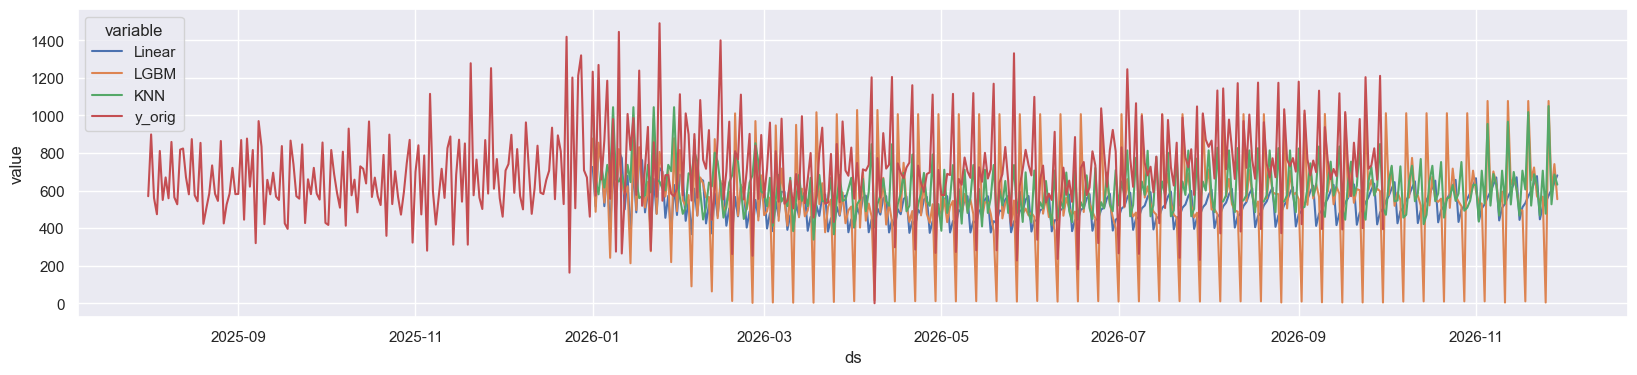

In [52]:
# convert to long (tidy) form
dfm = pd.melt(df_resultado,id_vars='ds',value_vars=['Linear','LGBM','KNN','y_orig'])
plt.figure(figsize=(20,4))
sns.lineplot(x='ds',y='value',data=dfm.query("ds>='2025-08-01'"),hue='variable')

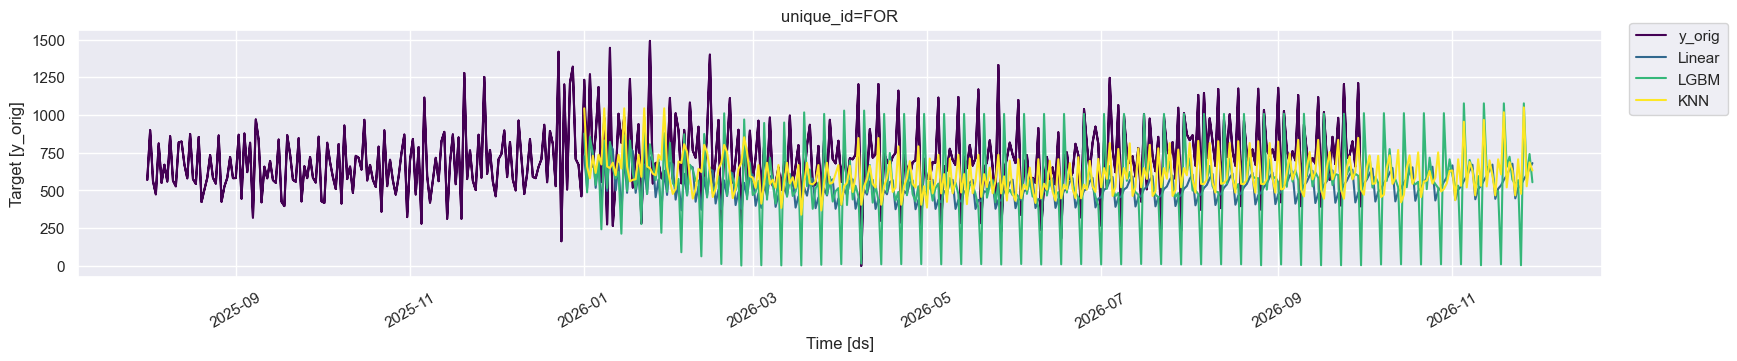

In [53]:
#sns.color_palette('muted')
plot_series(df_resultado.query("periodo >= '202508'"),\
            df_resultado.query("periodo >= '202508'"), models=['Linear','LGBM','KNN'],
            target_col='y_orig',max_ids=50,palette='viridis',
            engine='matplotlib')

In [54]:
df_resultado.query("periodo >= '202508'")[['y_orig','Linear','LGBM','KNN']]

,y_orig,Linear,LGBM,KNN
925,570.0,NaN,NaN,NaN
926,899.0,NaN,NaN,NaN
927,561.0,NaN,NaN,NaN
928,474.0,NaN,NaN,NaN
929,811.0,NaN,NaN,NaN
...,...,...,...,...
1406,NaN,537.0,4.0,477.0
1407,NaN,573.0,1077.0,1050.0
1408,NaN,604.0,591.0,527.0
1409,NaN,643.0,741.0,686.0


# Métricas de Avaliação

## MAE (MEAN ABSOLUTE ERROR)

In [55]:
# Usar o mesmo intervalo de previsão aplicado no treinamento.
metrica_final = loss(metrica = mae,df= df_resultado.query("ds>='2025-08-01'"),
                 modelos=['Linear','LGBM','KNN'],
    id_col='unique_id', target_col='y_orig').round(2)
metrica_final.sort_values(by=['unique_id','periodo'])

,unique_id,Linear,LGBM,KNN,periodo
0,FOR,NaN,NaN,NaN,202508
0,FOR,NaN,NaN,NaN,202509
0,FOR,NaN,NaN,NaN,202510
0,FOR,NaN,NaN,NaN,202511
0,FOR,NaN,NaN,NaN,202512
0,FOR,280.29,256.55,258.97,202601
0,FOR,271.96,264.50,244.14,202602
0,FOR,209.68,233.23,153.23,202603
0,FOR,275.00,282.93,184.53,202604
0,FOR,249.16,280.55,197.03,202605


## MAPE (MEAN ABSOLUTE PERCENTUAL ERROR)

In [56]:
metrica_final = loss(metrica = mape,df= df_resultado.query("ds>='2025-08-01'"),
                 modelos=['Linear','LGBM','KNN'],
    id_col='unique_id', target_col='y_orig').round(2)
metrica_final.sort_values(by=['unique_id','periodo'])

,unique_id,Linear,LGBM,KNN,periodo
0,FOR,NaN,NaN,NaN,202508
0,FOR,NaN,NaN,NaN,202509
0,FOR,NaN,NaN,NaN,202510
0,FOR,NaN,NaN,NaN,202511
0,FOR,NaN,NaN,NaN,202512
0,FOR,0.37,0.34,0.36,202601
0,FOR,0.34,0.37,0.37,202602
0,FOR,0.28,0.36,0.20,202603
0,FOR,0.35,0.42,0.25,202604
0,FOR,0.35,0.43,0.32,202605
